<a href="https://colab.research.google.com/github/Kamalll7/Final_Project_PCD-Kelompok_6/blob/main/notebook/02_Number_Plate_Detection_ROI_HOG_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---
## 1. Pendahuluan

### 1.1 Latar Belakang Singkat

Undang-Undang Nomor 22 Tahun 2009 mewajibkan kendaraan bermotor yang beroperasi di jalan
dilengkapi **Tanda Nomor Kendaraan Bermotor (TNKB)**. Deteksi keberadaan plat nomor merupakan
langkah awal yang krusial dalam sistem *Automatic License Plate Recognition* (ALPR), sebelum
tahap segmentasi dan pengenalan karakter.

### 1.2 Rumusan Masalah yang Dijawab Notebook Ini

> **Bagaimana mendeteksi keberadaan plat nomor pada sepeda motor menggunakan metode
> pengolahan citra digital dan machine learning?** (Rumusan Masalah #2)

### 1.3 Tujuan

Mengembangkan dan mengevaluasi metode deteksi keberadaan plat nomor sepeda motor menggunakan
**RoI** untuk mempersempit area pencarian, **HOG** untuk mengekstraksi deskriptor tepi/gradien,
dan **SVM** untuk klasifikasi biner.

### 1.4 Mengapa Deteksi Plat Motor Lebih Sulit daripada Plat Mobil?

Proposal §2.6 mencatat beberapa tantangan spesifik:

1. **Latar belakang kompleks** — plat motor bercampur dengan bodi kendaraan, knalpot, rantai,
   dan elemen lain di sekitarnya, berbeda dengan plat mobil yang relatif bersih.
2. **Ukuran kecil dan orientasi bervariasi** — plat motor lebih kecil dan dapat miring
   (*yaw*, *pitch*, *roll*).
3. **Literatur lebih jarang** — deteksi plat motor jauh lebih sedikit diteliti dibanding plat mobil.

### 1.5 Strategi: RoI Dulu, Baru Cari Plat

Hsu et al. (2015) — dirujuk proposal §2.6 — membandingkan dua skema:

| Skema | Cara kerja | Hasil |
|---|---|---|
| **Deteksi motor dulu**, lalu cari plat di dalamnya | meniru cara kerja visual manusia | **false positive jauh lebih sedikit**, deteksi lebih cepat |
| Deteksi plat langsung pada seluruh citra | seperti *sliding window* pada piramida citra | lebih banyak false positive, lebih lambat |

Contoh angka dari studi tersebut: deteksi motor **279 ms**, lalu plat hanya butuh **~8 ms**
tambahan di dalam area motor — jauh lebih cepat dibanding memindai seluruh citra.

**Karena itu notebook ini mengadopsi skema pertama**: RoI ditentukan lebih dulu (dari anotasi
`rider`), lalu pencarian plat dilakukan **hanya di dalam RoI tersebut**.

---
## 2. Setup Environment

Dirancang untuk **Google Colab** (sesuai §3.10 proposal) maupun eksekusi lokal.

**Perangkat lunak** (§3.10): `Python`, `OpenCV`, `scikit-image` (HOG), `scikit-learn` (SVM & metrik),
`NumPy`, `Matplotlib`, `Pandas`.

In [1]:
import sys, subprocess

REQUIRED = ["opencv-python-headless", "scikit-image", "scikit-learn",
            "matplotlib", "pandas", "numpy", "pillow"]

def _ensure(pkgs):
    missing = []
    for p in pkgs:
        mod = {"opencv-python-headless": "cv2", "scikit-image": "skimage",
               "scikit-learn": "sklearn", "pillow": "PIL"}.get(p, p)
        try:
            __import__(mod)
        except ImportError:
            missing.append(p)
    if missing:
        print("Memasang:", missing)
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=False)

_ensure(REQUIRED)
print("Dependensi siap.")

Dependensi siap.


In [2]:
import os, json, random, warnings, itertools
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from skimage.feature import hog
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (confusion_matrix, accuracy_score, precision_score,
                             recall_score, f1_score, cohen_kappa_score,
                             roc_curve, auc, classification_report,
                             precision_recall_curve, average_precision_score)

warnings.filterwarnings("ignore")

# ---- Reproducibility -------------------------------------------------------
SEED = 7
random.seed(SEED)
np.random.seed(SEED)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 110,
    "font.size": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
})

import sklearn, skimage
print("NumPy       :", np.__version__)
print("OpenCV      :", cv2.__version__)
print("scikit-learn:", sklearn.__version__)
print("scikit-image:", skimage.__version__)

NumPy       : 2.4.6
OpenCV      : 5.0.0
scikit-learn: 1.6.1
scikit-image: 0.25.2


---
## 3. Akuisisi Dataset

Dataset yang sama dengan Jalur 1, dengan struktur anotasi **YOLO**:

```
dataset/
├── train/{images,labels}/
└── val/{images,labels}/
```

**Kelas:**

| ID | Nama kelas |
|---|---|
| 0 | `with helmet` |
| 1 | `without helmet` |
| 2 | `rider` |
| 3 | `number plate` |

Kelas yang dipakai notebook ini: **`rider`** (untuk menentukan RoI) dan
**`number plate`** (sebagai *ground truth*).

In [3]:
DATASET_SLUG = "aneesarom/rider-with-helmet-without-helmet-number-plate"
CLASS_NAMES  = ["with helmet", "without helmet", "rider", "number plate"]

def _looks_like_dataset(p: Path) -> bool:
    return (p / "train" / "images").is_dir() and (p / "train" / "labels").is_dir()

def resolve_dataset() -> Path:
    candidates = []
    env = os.environ.get("PCD_DATASET_DIR")
    if env:
        candidates.append(Path(env))
    candidates += [Path("./dataset"), Path("../dataset"), Path("/content/dataset"),
                   Path.home() / ".cache/kagglehub/datasets/aneesarom/rider-with-helmet-without-helmet-number-plate"]
    for base in candidates:
        if not base.exists():
            continue
        if _looks_like_dataset(base):
            return base
        for sub in base.rglob("train"):
            if (sub / "images").is_dir() and (sub / "labels").is_dir():
                return sub.parent
    print("Dataset belum ditemukan secara lokal, mengunduh via kagglehub ...")
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=False)
        import kagglehub
    root = Path(kagglehub.dataset_download(DATASET_SLUG))
    for sub in [root] + list(root.rglob("*")):
        if _looks_like_dataset(sub):
            return sub
    raise FileNotFoundError("Struktur dataset tidak dikenali setelah unduhan.")

DATA_ROOT = resolve_dataset()
print("Dataset root :", DATA_ROOT.resolve())
print("Train images :", len(list((DATA_ROOT / 'train' / 'images').glob('*'))))
print("Val images   :", len(list((DATA_ROOT / 'val' / 'images').glob('*'))))

Dataset belum ditemukan secara lokal, mengunduh via kagglehub ...


100%|██████████| 74.6M/74.6M [00:00<00:00, 192MB/s]

Extracting files...


Dataset root : /root/.cache/kagglehub/datasets/aneesarom/rider-with-helmet-without-helmet-number-plate/versions/3
Train images : 104
Val images   : 20


### 3.1 Pembaca Citra yang Robust

Satu berkas berekstensi `.jpg` pada dataset sebenarnya berformat **AVIF**, sehingga `cv2.imread()`
mengembalikan `None`. Digunakan pembaca dengan *fallback* ke `Pillow` agar tidak ada data yang
hilang secara diam-diam.

In [4]:
def imread_robust(path) -> np.ndarray:
    img = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if img is not None:
        return img
    from PIL import Image
    with Image.open(path) as im:
        arr = np.array(im.convert("RGB"))
    return cv2.cvtColor(arr, cv2.COLOR_RGB2BGR)


def parse_label_file(path: Path):
    boxes = []
    for line in path.read_text().strip().splitlines():
        parts = line.split()
        if len(parts) < 5:
            continue
        cls = int(parts[0])
        x, y, w, h = map(float, parts[1:5])
        boxes.append({"cls": cls,
                      "x1": x - w / 2, "y1": y - h / 2,
                      "x2": x + w / 2, "y2": y + h / 2})
    return boxes


def build_index(root: Path) -> pd.DataFrame:
    rows = []
    for split in ("train", "val"):
        for lbl in sorted((root / split / "labels").glob("*.txt")):
            stem = lbl.stem
            img_path = root / split / "images" / (stem + ".jpg")
            if not img_path.exists():
                hits = list((root / split / "images").glob(stem + ".*"))
                if not hits:
                    continue
                img_path = hits[0]
            boxes = parse_label_file(lbl)
            row = {"split": split, "stem": stem, "image_path": str(img_path),
                   "n_objects": len(boxes), "boxes": boxes}
            for cid, cname in enumerate(CLASS_NAMES):
                row["n_" + cname] = sum(1 for b in boxes if b["cls"] == cid)
            rows.append(row)
    return pd.DataFrame(rows)

df = build_index(DATA_ROOT)
print(f"Total citra terindeks: {len(df)}")

bad = [p for p in df["image_path"] if imread_robust(p) is None]
print("Citra gagal dibaca:", len(bad))

total = {c: int(df["n_" + c].sum()) for c in CLASS_NAMES}
print("\nJumlah bounding box per kelas:")
for k, v in total.items():
    print(f"  {k:16s} : {v}")

Total citra terindeks: 124
Citra gagal dibaca: 0

Jumlah bounding box per kelas:
  with helmet      : 77
  without helmet   : 108
  rider            : 143
  number plate     : 138


---
## 4. Eksplorasi Data: Geometri Plat Nomor

Karena jalur ini bertumpu pada **RoI**, analisis paling penting adalah **di mana plat nomor
berada relatif terhadap *bounding box* pengendara**. Analisis ini menjadi dasar kuantitatif
penentuan RoI pada §3.5 proposal.

Selain posisi, dianalisis pula **ukuran dan rasio aspek** plat — keduanya menentukan
ukuran *window* dan skala yang dipakai pada tahap pembentukan kandidat.

In [5]:
def iou_norm(a, b):
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    iw, ih = max(0.0, ix2 - ix1), max(0.0, iy2 - iy1)
    inter = iw * ih
    ua = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / ua if ua > 0 else 0.0

def box_tuple(b):
    return (b["x1"], b["y1"], b["x2"], b["y2"])

# Relasi plat <-> pengendara
plate_rel = []
for _, row in df.iterrows():
    riders = [b for b in row["boxes"] if b["cls"] == 2]
    plates = [b for b in row["boxes"] if b["cls"] == 3]
    for r in riders:
        rb = box_tuple(r)
        rw, rh = rb[2] - rb[0], rb[3] - rb[1]
        for p in plates:
            pb = box_tuple(p)
            if iou_norm(rb, pb) <= 0.001:
                continue
            plate_rel.append({
                "cx_rel": ((pb[0] + pb[2]) / 2 - rb[0]) / rw,
                "cy_rel": ((pb[1] + pb[3]) / 2 - rb[1]) / rh,
                "w_rel": (pb[2] - pb[0]) / rw,
                "h_rel": (pb[3] - pb[1]) / rh,
            })

pr_df = pd.DataFrame(plate_rel)
print("Pasangan plat-pengendara:", len(pr_df))
print()
for col in ["cx_rel", "cy_rel", "w_rel", "h_rel"]:
    q = pr_df[col].quantile([0.05, 0.25, 0.50, 0.75, 0.95])
    print(f"{col:8s}  p5={q.iloc[0]:.3f}  p25={q.iloc[1]:.3f}  "
          f"med={q.iloc[2]:.3f}  p75={q.iloc[3]:.3f}  p95={q.iloc[4]:.3f}")

Pasangan plat-pengendara: 145

cx_rel    p5=0.148  p25=0.257  med=0.458  p75=0.587  p95=0.840
cy_rel    p5=0.469  p25=0.566  med=0.652  p75=0.733  p95=0.859
w_rel     p5=0.184  p25=0.244  med=0.303  p75=0.356  p95=0.439
h_rel     p5=0.033  p25=0.046  med=0.069  p75=0.084  p95=0.103


In [6]:
# Ukuran plat dalam piksel (perlu resolusi asli) dan rasio aspeknya
px_w, px_h, aspect = [], [], []
for _, row in df.iterrows():
    img = imread_robust(row["image_path"])
    if img is None:
        continue
    H, W = img.shape[:2]
    for b in row["boxes"]:
        if b["cls"] != 3:
            continue
        w = (b["x2"] - b["x1"]) * W
        h = (b["y2"] - b["y1"]) * H
        if w < 2 or h < 2:
            continue
        px_w.append(w); px_h.append(h); aspect.append(w / h)

px_w, px_h, aspect = map(np.array, (px_w, px_h, aspect))
print(f"Lebar plat (px)   : p10={np.percentile(px_w,10):.0f}  median={np.median(px_w):.0f}  "
      f"p90={np.percentile(px_w,90):.0f}")
print(f"Tinggi plat (px)  : p10={np.percentile(px_h,10):.0f}  median={np.median(px_h):.0f}  "
      f"p90={np.percentile(px_h,90):.0f}")
print(f"Rasio aspek w/h   : p10={np.percentile(aspect,10):.2f}  median={np.median(aspect):.2f}  "
      f"p90={np.percentile(aspect,90):.2f}")
print(f"\n-> Rasio aspek plat (median {np.median(aspect):.2f}) menjadi acuan AR_WINDOW pada §7")

Lebar plat (px)   : p10=67  median=106  p90=180
Tinggi plat (px)  : p10=19  median=47  p90=75
Rasio aspek w/h   : p10=1.56  median=2.16  p90=4.92

-> Rasio aspek plat (median 2.16) menjadi acuan AR_WINDOW pada §7


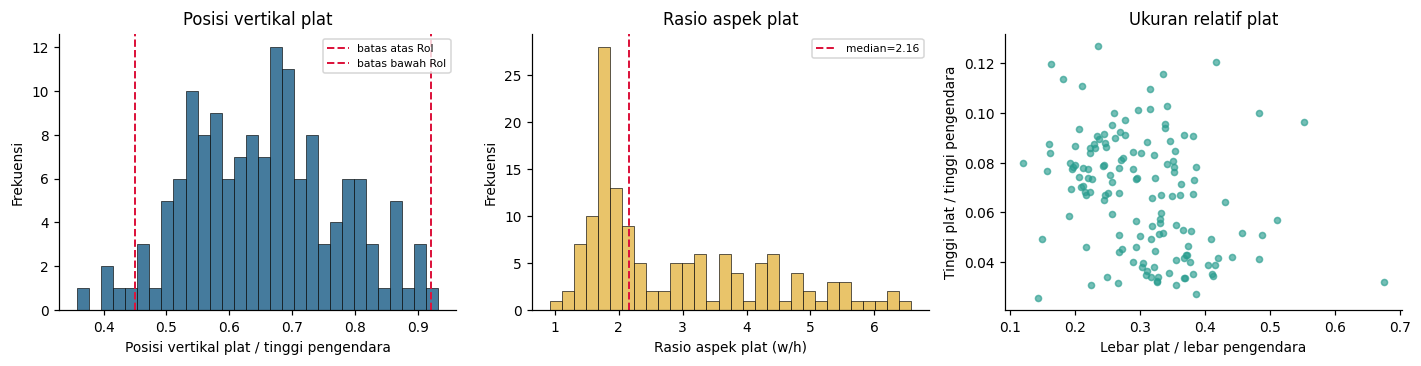

Proporsi plat yang pusatnya berada di antara 45%–92% tinggi pengendara: 96.6%


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))

axes[0].hist(pr_df["cy_rel"], bins=30, color="#457b9d", edgecolor="black", linewidth=0.4)
axes[0].axvline(0.45, color="crimson", ls="--", lw=1.3, label="batas atas RoI")
axes[0].axvline(0.92, color="crimson", ls="--", lw=1.3, label="batas bawah RoI")
axes[0].set_xlabel("Posisi vertikal plat / tinggi pengendara")
axes[0].set_ylabel("Frekuensi")
axes[0].set_title("Posisi vertikal plat")
axes[0].legend(fontsize=7)

axes[1].hist(aspect, bins=30, color="#e9c46a", edgecolor="black", linewidth=0.4)
axes[1].axvline(np.median(aspect), color="crimson", ls="--", lw=1.3,
                label=f"median={np.median(aspect):.2f}")
axes[1].set_xlabel("Rasio aspek plat (w/h)")
axes[1].set_ylabel("Frekuensi")
axes[1].set_title("Rasio aspek plat")
axes[1].legend(fontsize=7)

axes[2].scatter(pr_df["w_rel"], pr_df["h_rel"], s=16, alpha=0.65, color="#2a9d8f")
axes[2].set_xlabel("Lebar plat / lebar pengendara")
axes[2].set_ylabel("Tinggi plat / tinggi pengendara")
axes[2].set_title("Ukuran relatif plat")

plt.tight_layout()
plt.show()

print("Proporsi plat yang pusatnya berada di antara 45%%–92%% tinggi pengendara: %.1f%%"
      % (100 * pr_df["cy_rel"].between(0.45, 0.92).mean()))

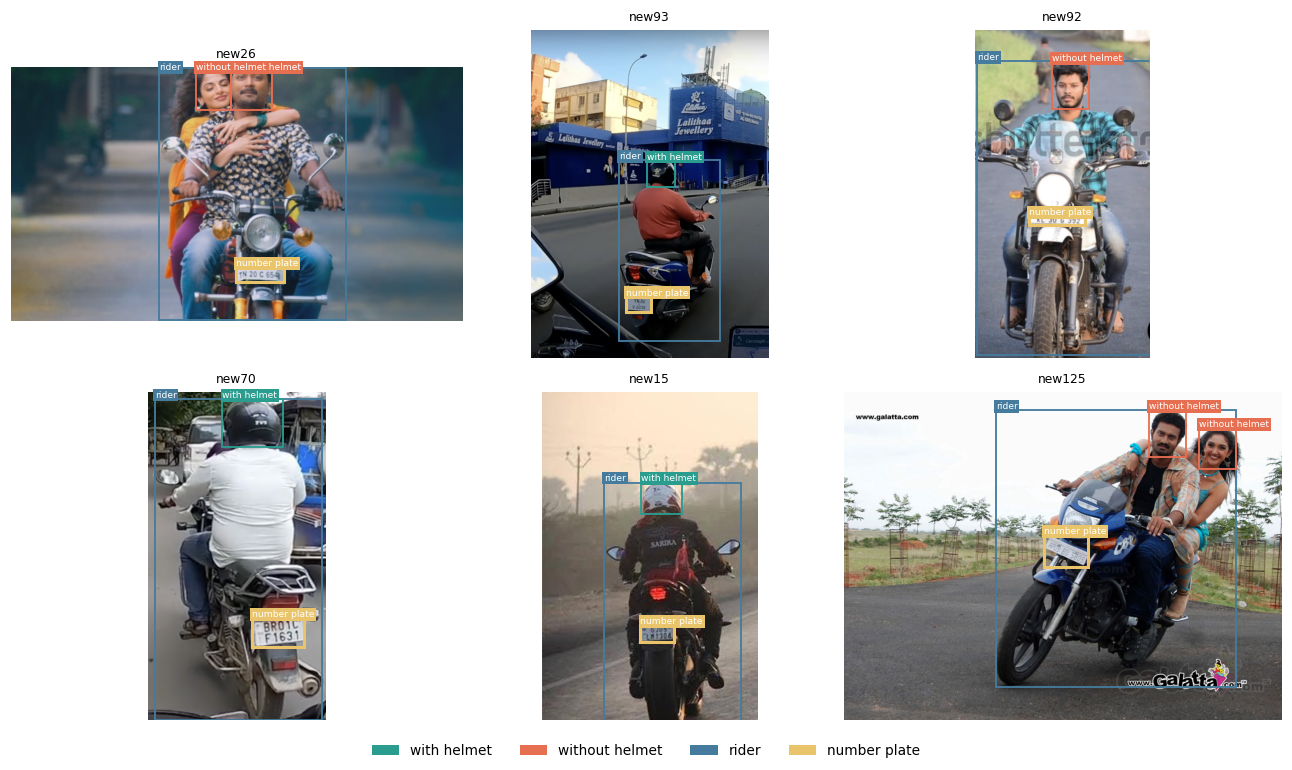

In [8]:
# Visualisasi contoh dengan anotasi plat
COLORS = {0: "#2a9d8f", 1: "#e76f51", 2: "#457b9d", 3: "#e9c46a"}

sample = df[df["n_number plate"] > 0].sample(6, random_state=SEED)
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, (_, row) in zip(axes.ravel(), sample.iterrows()):
    img = imread_robust(row["image_path"])
    H, W = img.shape[:2]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    for b in row["boxes"]:
        x1, y1 = b["x1"] * W, b["y1"] * H
        w, h = (b["x2"] - b["x1"]) * W, (b["y2"] - b["y1"]) * H
        ax.add_patch(Rectangle((x1, y1), w, h, fill=False,
                               edgecolor=COLORS[b["cls"]],
                               lw=2.0 if b["cls"] == 3 else 1.2))
        ax.text(x1, max(y1 - 3, 8), CLASS_NAMES[b["cls"]], fontsize=6, color="white",
                bbox=dict(fc=COLORS[b["cls"]], ec="none", pad=1.2))
    ax.set_title(row["stem"], fontsize=8)
    ax.axis("off")

handles = [Rectangle((0, 0), 1, 1, fc=COLORS[i], ec="none") for i in range(4)]
fig.legend(handles, CLASS_NAMES, loc="lower center", ncol=4, frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

---
## 5. Pra-pemrosesan Citra  ·  *(Proposal §3.4)*

Tiga tahap sesuai proposal:

| Tahap | Operasi | Alasan |
|---|---|---|
| 1 | **Resize** | mengurangi jumlah piksel → beban komputasi turun |
| 2 | **Grayscale** | fokus pada bentuk/tepi/intensitas; HOG bekerja pada intensitas |
| 3 | **Peningkatan kontras (CLAHE)** | mempertegas perbedaan intensitas objek vs latar |

> **Catatan metodologis.** **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*)
> digunakan karena bersifat **adaptif per wilayah** dan **membatasi amplifikasi noise**
> melalui *clip limit*. Hal ini penting untuk plat nomor: karakter plat adalah pola
> terang-gelap berfrekuensi tinggi, sehingga peningkatan kontras yang terlalu agresif
> justru akan menguatkan noise. Untuk plat, nilai `clipLimit` dibuat lebih rendah
> (1.5) dibanding jalur helm (2.0) agar tepi karakter tidak "pecah".

In [9]:
CLAHE_CLIP = 1.5
CLAHE_GRID = (8, 8)
_clahe = cv2.createCLAHE(clipLimit=CLAHE_CLIP, tileGridSize=CLAHE_GRID)

def to_grayscale(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def enhance_contrast(gray):
    return _clahe.apply(gray)

def preprocess_gray(img):
    """Pra-pemrosesan untuk jalur plat: grayscale -> CLAHE."""
    return enhance_contrast(to_grayscale(img))

print("Fungsi pra-pemrosesan siap. CLAHE clipLimit =", CLAHE_CLIP)

Fungsi pra-pemrosesan siap. CLAHE clipLimit = 1.5


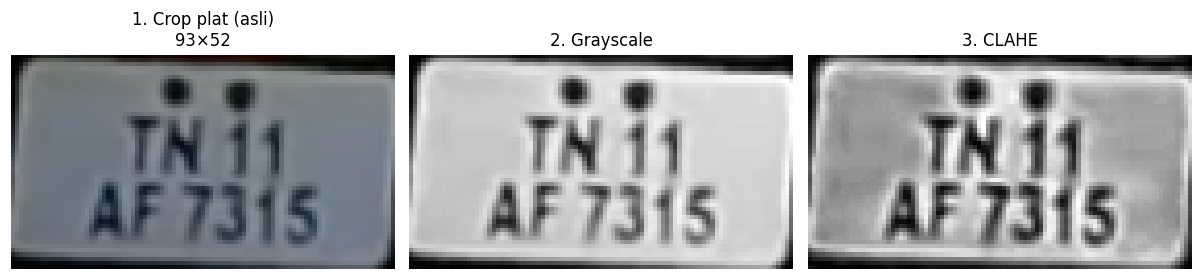

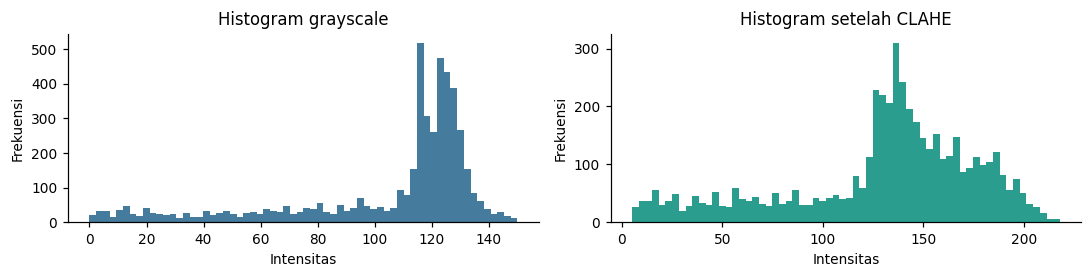

In [10]:
# Demonstrasi pra-pemrosesan pada RoI plat
row = df[df["n_number plate"] > 0].iloc[0]
img = imread_robust(row["image_path"])
H, W = img.shape[:2]
plate = [b for b in row["boxes"] if b["cls"] == 3][0]
pb = box_tuple(plate)
X1, Y1 = int(pb[0]*W), int(pb[1]*H)
X2, Y2 = int(pb[2]*W), int(pb[3]*H)
crop = img[Y1:Y2, X1:X2]

gray = to_grayscale(crop)
eq = enhance_contrast(gray)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
axes[0].imshow(cv2.cvtColor(crop, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"1. Crop plat (asli)\n{crop.shape[1]}×{crop.shape[0]}")
axes[1].imshow(gray, cmap="gray")
axes[1].set_title("2. Grayscale")
axes[2].imshow(eq, cmap="gray")
axes[2].set_title("3. CLAHE")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 2.6))
axes[0].hist(gray.ravel(), bins=64, color="#457b9d")
axes[0].set_title("Histogram grayscale")
axes[1].hist(eq.ravel(), bins=64, color="#2a9d8f")
axes[1].set_title("Histogram setelah CLAHE")
for ax in axes:
    ax.set_xlabel("Intensitas"); ax.set_ylabel("Frekuensi")
plt.tight_layout()
plt.show()

---
## 6. Penentuan Region of Interest (RoI)  ·  *(Proposal §3.5)*

Citra pada dataset memuat banyak area tidak relevan: jalan, latar belakang, dan bagian motor
yang bukan plat. RoI memfokuskan proses pada area yang mengandung plat sehingga:

- fitur yang diekstraksi lebih merepresentasikan objek,
- **jumlah kandidat yang harus dievaluasi turun drastis** → pengolahan lebih efisien.

### Definisi RoI Plat

Berdasarkan EDA §4, plat berada pada **45%–92% tinggi** *bounding box* pengendara, dengan
posisi horizontal 10%–95% lebarnya. RoI didefinisikan sebagai pita tersebut.

```
┌──────────────────────┐  ← y = 0%   (kepala/helm)
│                      │
├──────────────────────┤  ← y = 45%  ┬
│   ███ RoI PLAT ███   │             │ area pencarian plat
├──────────────────────┤  ← y = 92%  ┴
│                      │
└──────────────────────┘  ← y = 100%
```

Membatasi pencarian pada pita ini memangkas area yang harus dipindai menjadi sekitar
**47%** dari luas *bounding box* pengendara, dan jauh lebih kecil lagi dibanding seluruh citra.

> Ini adalah penerapan langsung temuan Hsu et al. (2015): **mempersempit area pencarian
> sebelum mencari plat mengurangi false positive dan mempercepat deteksi** (§2.6 proposal).

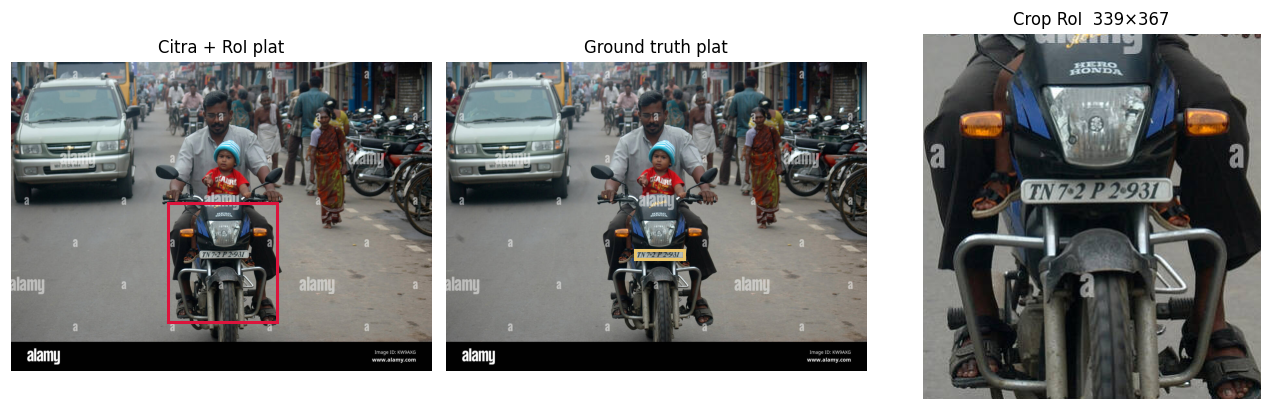

Luas RoI / luas citra : 10.0%


In [11]:
ROI_Y_TOP    = 0.45
ROI_Y_BOTTOM = 0.92
ROI_X_LO     = 0.10
ROI_X_HI     = 0.95

def rider_roi_px(img_shape, rider_box,
                 y_top=ROI_Y_TOP, y_bottom=ROI_Y_BOTTOM,
                 x_lo=ROI_X_LO, x_hi=ROI_X_HI):
    """RoI plat dalam koordinat piksel dari box pengendara ternormalisasi."""
    H, W = img_shape[:2]
    x1, y1, x2, y2 = rider_box
    w, h = x2 - x1, y2 - y1
    X1 = int(np.clip((x1 + x_lo * w) * W, 0, W - 1))
    X2 = int(np.clip((x1 + x_hi * w) * W, 0, W - 1))
    Y1 = int(np.clip((y1 + y_top * h) * H, 0, H - 1))
    Y2 = int(np.clip((y1 + y_bottom * h) * H, 0, H - 1))
    return X1, Y1, X2, Y2

def crop_px(img, box):
    X1, Y1, X2, Y2 = box
    if X2 - X1 < 8 or Y2 - Y1 < 8:
        return None
    return img[Y1:Y2, X1:X2]

# Demonstrasi RoI
row = df[(df["n_rider"] > 0) & (df["n_number plate"] > 0)].iloc[2]
img = imread_robust(row["image_path"])
H, W = img.shape[:2]
rider = [b for b in row["boxes"] if b["cls"] == 2][0]
roi = rider_roi_px(img.shape, box_tuple(rider))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
axes[0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
axes[0].add_patch(Rectangle((roi[0], roi[1]), roi[2]-roi[0], roi[3]-roi[1],
                            fill=False, ec="crimson", lw=2))
axes[0].set_title("Citra + RoI plat")
axes[1].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
for b in row["boxes"]:
    if b["cls"] == 3:
        axes[1].add_patch(Rectangle((b["x1"]*W, b["y1"]*H), (b["x2"]-b["x1"])*W,
                                    (b["y2"]-b["y1"])*H, fill=False, ec="#e9c46a", lw=2))
axes[1].set_title("Ground truth plat")
axes[2].imshow(cv2.cvtColor(crop_px(img, roi), cv2.COLOR_BGR2RGB))
axes[2].set_title(f"Crop RoI  {roi[2]-roi[0]}×{roi[3]-roi[1]}")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

roi_area = (roi[2]-roi[0]) * (roi[3]-roi[1])
print(f"Luas RoI / luas citra : {roi_area/(W*H):.1%}")

---
## 7. Pembentukan Kandidat dengan Sliding Window Multi-Skala

Di dalam RoI, sistem perlu menemukan **calon lokasi plat** (*candidate proposals*) yang kemudian
dinilai oleh classifier. Pendekatan yang dipakai adalah **sliding window multi-skala** —
pendekatan klasik yang disebut pada proposal §2.6 sebagai cara kerja *sliding window* pada
visi komputer konvensional.

### Mengapa multi-skala?

Ukuran plat bervariasi (EDA §4: lebar plat 67–175 px, median 106 px). Karena itu dipakai
beberapa skala relatif terhadap lebar RoI:

| Parameter | Nilai | Alasan |
|---|---|---|
| Skala lebar | 20%, 28%, 36%, 44% dari lebar RoI | mencakup variasi ukuran plat |
| Rasio aspek | 2.1 (median hasil EDA) | bentuk plat |
| Langkah (*stride*) | 50% dari ukuran window | kompromi antara cakupan dan jumlah kandidat |

Window yang sangat kecil dibuang (lebar < 24 px) karena plat sekecil itu tidak dapat
dideskripsikan dengan andal oleh HOG berukuran 96×48.

In [12]:
WIN_SIZE     = (96, 48)          # (lebar, tinggi) input HOG untuk plat
AR_WINDOW    = 2.1               # rasio aspek window
SCALES       = (0.20, 0.28, 0.36, 0.44)
STRIDE       = 0.50
MIN_WIN_W    = 24

HOG_ORIENT   = 9
HOG_PPC      = (8, 8)
HOG_CPB      = (2, 2)
HOG_NORM     = "L2-Hys"

def sliding_windows(X1, Y1, X2, Y2,
                    scales=SCALES, stride=STRIDE, ar=AR_WINDOW, min_w=MIN_WIN_W):
    """Hasilkan daftar window (x1,y1,x2,y2) di dalam RoI pada beberapa skala."""
    RW, RH = X2 - X1, Y2 - Y1
    out = []
    for sc in scales:
        w = max(min_w, int(RW * sc))
        h = max(12, int(round(w / ar)))
        if w > RW or h > RH:
            continue
        sx = max(6, int(w * stride))
        sy = max(4, int(h * stride))
        for yy in range(Y1, Y2 - h + 1, sy):
            for xx in range(X1, X2 - w + 1, sx):
                out.append((xx, yy, xx + w, yy + h))
    return out

def count_windows_for_row(row):
    img = imread_robust(row["image_path"])
    if img is None:
        return 0, 0
    n = 0
    for r in [b for b in row["boxes"] if b["cls"] == 2]:
        X1, Y1, X2, Y2 = rider_roi_px(img.shape, box_tuple(r))
        n += len(sliding_windows(X1, Y1, X2, Y2))
    return n, img.shape[0] * img.shape[1]

counts = [count_windows_for_row(r)[0] for _, r in df.iterrows()]
print(f"Rata-rata kandidat window per citra : {np.mean(counts):.0f}")
print(f"Median                              : {np.median(counts):.0f}")
print(f"Maksimum                            : {np.max(counts)}")
print(f"\nSebagai perbandingan, sliding window pada SELURUH citra dengan 4 skala")
print("yang sama akan menghasilkan ribuan kandidat per citra — inilah alasan RoI penting.")

Rata-rata kandidat window per citra : 370
Median                              : 328
Maksimum                            : 1652

Sebagai perbandingan, sliding window pada SELURUH citra dengan 4 skala
yang sama akan menghasilkan ribuan kandidat per citra — inilah alasan RoI penting.


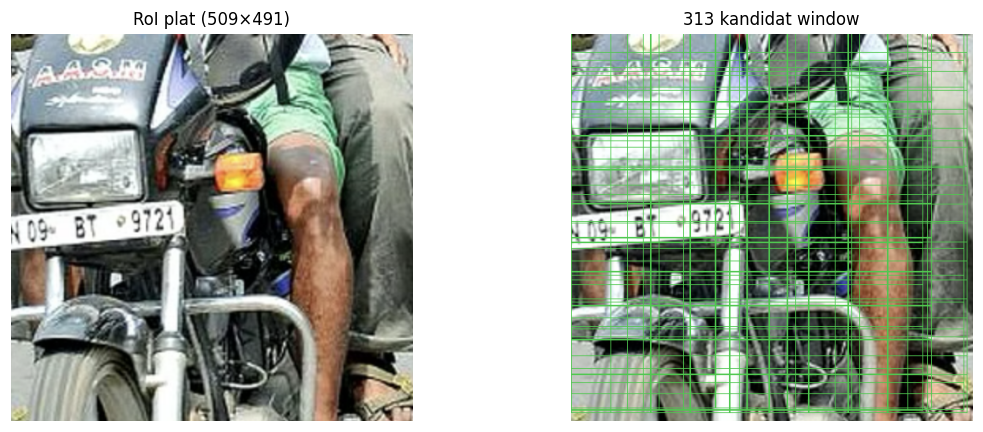

In [13]:
# Visualisasi kandidat window di dalam RoI
row = df[(df["n_rider"] > 0) & (df["n_number plate"] > 0)].iloc[1]
img = imread_robust(row["image_path"])
H, W = img.shape[:2]
rider = [b for b in row["boxes"] if b["cls"] == 2][0]
roi = rider_roi_px(img.shape, box_tuple(rider))
wins = sliding_windows(*roi)

vis = img.copy()
for (a1, b1, a2, b2) in wins:
    cv2.rectangle(vis, (a1, b1), (a2, b2), (80, 200, 80), 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].imshow(cv2.cvtColor(crop_px(img, roi), cv2.COLOR_BGR2RGB))
axes[0].set_title(f"RoI plat ({roi[2]-roi[0]}×{roi[3]-roi[1]})")
axes[1].imshow(cv2.cvtColor(crop_px(vis, roi), cv2.COLOR_BGR2RGB))
axes[1].set_title(f"{len(wins)} kandidat window")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

---
## 8. Ekstraksi Fitur dengan HOG  ·  *(Proposal §3.6)*

Setiap kandidat window diseragamkan ke **96 × 48 piksel**, lalu dideskripsikan dengan HOG.

### Mengapa HOG Cocok untuk Plat Nomor?

Plat nomor memiliki **pola garis dan tepi yang sangat khas**: deretan karakter dengan
orientasi gradien dominan vertikal dan horizontal. HOG merangkum distribusi orientasi gradien
ini menjadi vektor numerik yang **invarian terhadap perubahan iluminasi** (karena normalisasi
blok) namun tetap sensitif terhadap struktur tepi — tepat untuk membedakan area plat dari
bodi motor yang permukaannya lebih halus atau berpola acak.

### Konfigurasi

| Parameter | Nilai |
|---|---|
| Window | 96 × 48 px (rasio 2:1, mendekati rasio plat) |
| `orientations` | 9 (0°–180°, *unsigned*) |
| `pixels_per_cell` | 8 × 8 |
| `cells_per_block` | 2 × 2 |
| `block_norm` | `L2-Hys` |

Dimensi vektor fitur: **1980**.

In [14]:
def extract_hog(gray_patch, win=WIN_SIZE, visualize=False):
    """Ekstraksi vektor fitur HOG dari patch grayscale."""
    g = cv2.resize(gray_patch, win, interpolation=cv2.INTER_AREA)
    return hog(g,
               orientations=HOG_ORIENT,
               pixels_per_cell=HOG_PPC,
               cells_per_block=HOG_CPB,
               block_norm=HOG_NORM,
               visualize=visualize,
               feature_vector=True)

def patch_gray(img_gray, box):
    X1, Y1, X2, Y2 = box
    return img_gray[Y1:Y2, X1:X2]

_probe = extract_hog(np.zeros((48, 96), np.uint8))
print("Dimensi vektor fitur HOG:", _probe.shape[0])

Dimensi vektor fitur HOG: 1980


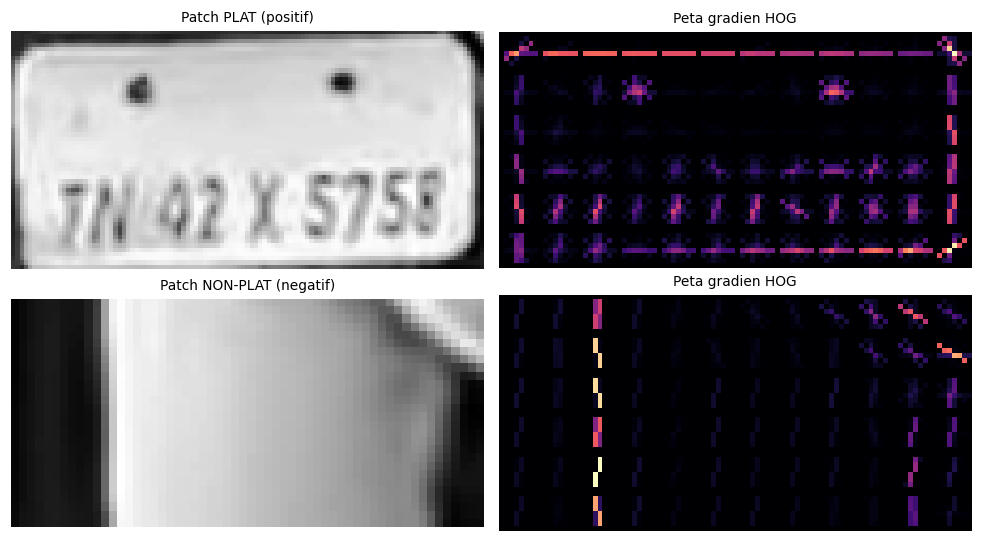

In [15]:
# Visualisasi HOG pada patch plat vs patch non-plat
row = df[(df["n_rider"] > 0) & (df["n_number plate"] > 0)].iloc[3]
img = imread_robust(row["image_path"])
H, W = img.shape[:2]
gray = preprocess_gray(img)

plate = [b for b in row["boxes"] if b["cls"] == 3][0]
pb = box_tuple(plate)
plate_box = (int(pb[0]*W), int(pb[1]*H), int(pb[2]*W), int(pb[3]*H))

# patch negatif: window acak di RoI yang tidak menimpa plat
rng = np.random.RandomState(SEED)
rider = [b for b in row["boxes"] if b["cls"] == 2][0]
roi = rider_roi_px(img.shape, box_tuple(rider))
neg_box = None
for cand in sliding_windows(*roi):
    cn = (cand[0]/W, cand[1]/H, cand[2]/W, cand[3]/H)
    if iou_norm(cn, pb) < 0.05:
        neg_box = cand
        break

fig, axes = plt.subplots(2, 2, figsize=(9, 5))
for i, (box, title) in enumerate([(plate_box, "Patch PLAT (positif)"),
                                 (neg_box, "Patch NON-PLAT (negatif)")]):
    patch = patch_gray(gray, box)
    if patch.size == 0:
        continue
    fd, himg = extract_hog(patch, visualize=True)
    axes[i, 0].imshow(patch, cmap="gray")
    axes[i, 0].set_title(title, fontsize=9)
    axes[i, 1].imshow(himg, cmap="magma")
    axes[i, 1].set_title("Peta gradien HOG", fontsize=9)
    for ax in axes[i]:
        ax.axis("off")
plt.tight_layout()
plt.show()

---
## 9. Konstruksi Dataset Klasifikasi Patch

Classifier SVM dilatih pada **level patch**, bukan level citra. Dua jenis sampel dibentuk:

| Jenis | Cara memperoleh | Label |
|---|---|---|
| **Positif** | Potong tepat pada *bounding box* plat *ground truth* | 1 |
| **Negatif** | Window acak di dalam RoI yang **tidak** menimpa plat (IoU < 0.20) | 0 |

### Mengapa banyak sampel negatif?

Rasio alami plat terhadap seluruh kandidat window sangat kecil (plat menempati sebagian kecil
RoI). Jika jumlah negatif dan positif seimbang, classifier akan terlalu sering menghasilkan
*false positive* saat inferensi karena belum pernah melihat cukup banyak variasi latar belakang.
Karena itu ditambahkan **14 sampel negatif per pengendara**, ditambah **hard-negative mining**
pada §10.

### Pencegahan Kebocoran Data

Split dilakukan **berdasarkan citra**: seluruh patch dari satu citra berada di satu split saja.
Jika tidak, patch positif dan negatif dari citra yang sama dapat muncul di latih dan uji
sekaligus — model akan menghafal latar belakang spesifik citra tersebut dan evaluasi menjadi
tidak valid.

In [16]:
N_NEG_PER_RIDER = 14
NEG_IOU_MAX     = 0.20

def rider_plate_boxes(boxes):
    return [b for b in boxes if b["cls"] == 3]

def collect_base_patches(df_sub, rng):
    """Kumpulkan patch positif (plat) dan negatif (acak di RoI) dari sekumpulan citra."""
    X, y = [], []
    for _, row in df_sub.iterrows():
        img = imread_robust(row["image_path"])
        if img is None:
            continue
        H, W = img.shape[:2]
        gray = preprocess_gray(img)
        plates = rider_plate_boxes(row["boxes"])
        plate_tuples = [box_tuple(p) for p in plates]

        # --- positif
        for pb in plate_tuples:
            X1 = int(np.clip(pb[0]*W, 0, W-1)); Y1 = int(np.clip(pb[1]*H, 0, H-1))
            X2 = int(np.clip(pb[2]*W, 0, W-1)); Y2 = int(np.clip(pb[3]*H, 0, H-1))
            if X2 - X1 < 8 or Y2 - Y1 < 5:
                continue
            patch = gray[Y1:Y2, X1:X2]
            if patch.size == 0:
                continue
            X.append(extract_hog(patch)); y.append(1)

        # --- negatif (acak di dalam RoI, tidak menimpa plat)
        for r in [b for b in row["boxes"] if b["cls"] == 2]:
            roi = rider_roi_px(img.shape, box_tuple(r))
            cands = sliding_windows(*roi)
            rng.shuffle(cands)
            got = 0
            for (a1, b1, a2, b2) in cands:
                nb = (a1/W, b1/H, a2/W, b2/H)
                if any(iou_norm(nb, pt) > NEG_IOU_MAX for pt in plate_tuples):
                    continue
                patch = gray[b1:b2, a1:a2]
                if patch.size == 0:
                    continue
                X.append(extract_hog(patch)); y.append(0)
                got += 1
                if got >= N_NEG_PER_RIDER:
                    break
    return np.array(X), np.array(y)

def mine_hard_negatives(df_sub, clf, rng, score_thr=-0.3, n_per_rider=12):
    """Hard-negative mining: ambil window yang SALAH dinilai tinggi oleh model saat ini."""
    X = []
    for _, row in df_sub.iterrows():
        img = imread_robust(row["image_path"])
        if img is None:
            continue
        H, W = img.shape[:2]
        gray = preprocess_gray(img)
        plate_tuples = [box_tuple(p) for p in rider_plate_boxes(row["boxes"])]
        for r in [b for b in row["boxes"] if b["cls"] == 2]:
            roi = rider_roi_px(img.shape, box_tuple(r))
            cands = sliding_windows(*roi)
            if not cands:
                continue
            feats = np.array([extract_hog(gray[b1:b2, a1:a2]) for a1, b1, a2, b2 in cands])
            scores = clf.decision_function(feats)
            got = 0
            for i in np.argsort(-scores):
                a1, b1, a2, b2 = cands[i]
                nb = (a1/W, b1/H, a2/W, b2/H)
                if any(iou_norm(nb, pt) > 0.25 for pt in plate_tuples):
                    continue
                if scores[i] < score_thr:
                    break
                X.append(feats[i]); got += 1
                if got >= n_per_rider:
                    break
    return np.array(X) if X else np.empty((0, _probe.shape[0]))

print("Fungsi pembentuk dataset patch siap.")

Fungsi pembentuk dataset patch siap.


In [17]:
# Split berdasarkan citra
unique_images = sorted(df["stem"].unique())
train_imgs, test_imgs = train_test_split(unique_images, test_size=0.30,
                                         random_state=SEED, shuffle=True)
train_set, test_set = set(train_imgs), set(test_imgs)
assert not (train_set & test_set)

df_train = df[df["stem"].isin(train_set)].reset_index(drop=True)
df_test  = df[df["stem"].isin(test_set)].reset_index(drop=True)

print(f"Citra latih : {len(df_train)}")
print(f"Citra uji   : {len(df_test)}")
print("Verifikasi: tidak ada irisan citra antara data latih dan uji.")

rng = np.random.RandomState(SEED)
X_train, y_train = collect_base_patches(df_train, rng)
X_test,  y_test  = collect_base_patches(df_test,  np.random.RandomState(SEED + 1))

print(f"\nPatch latih : {X_train.shape}  positif={int(y_train.sum())}  negatif={int((y_train==0).sum())}")
print(f"Patch uji   : {X_test.shape}  positif={int(y_test.sum())}  negatif={int((y_test==0).sum())}")

Citra latih : 86
Citra uji   : 38
Verifikasi: tidak ada irisan citra antara data latih dan uji.

Patch latih : (1466, 1980)  positif=94  negatif=1372
Patch uji   : (674, 1980)  positif=44  negatif=630


---
## 10. Klasifikasi dengan SVM  ·  

### 10.1 Prinsip Kerja

SVM mencari **hyperplane** yang memaksimalkan margin antar kelas:

$$\min_{w,b} \tfrac{1}{2}\lVert w \rVert^2 \quad \text{s.t.} \quad y_i (w^\top x_i + b) \ge 1$$

Dengan **soft margin** untuk data yang tidak sepenuhnya terpisah:

$$\min_{w,b,\xi} \tfrac{1}{2}\lVert w \rVert^2 + C \sum_i \xi_i$$

### 10.2 Hard-Negative Mining

Setelah model awal dilatih, model dijalankan pada data **latih** untuk menemukan window
yang **salah diberi skor tinggi** (false positive potensial). Window tersebut ditambahkan
sebagai sampel negatif, lalu model dilatih ulang. Proses ini diulang beberapa putaran.

Tujuan: mempersempit *decision boundary* pada area yang paling membingungkan model —
misalnya bodi motor yang memiliki tepi mirip karakter plat.

### 10.3 Pilihan Kernel

**Kernel linear** sesuai proposal §3.7: efisien untuk fitur HOG berdimensi tinggi (1980 dimensi)
dan memberikan keseimbangan akurasi–kecepatan yang terbaik menurut Hsu et al. (2015).
Standardisasi (`StandardScaler`) di-*fit* **hanya pada data latih**.

In [18]:
HARD_ROUNDS = 2
HARD_THR    = -0.3

X_cur, y_cur = X_train.copy(), y_train.copy()
model = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0, random_state=SEED))
model.fit(X_cur, y_cur)

history = []
for rnd in range(HARD_ROUNDS):
    X_hard = mine_hard_negatives(df_train, model, np.random.RandomState(SEED + 10 + rnd),
                                 score_thr=HARD_THR)
    if len(X_hard) == 0:
        print(f"Putaran {rnd+1}: tidak ada hard negative baru, berhenti.")
        break
    X_cur = np.vstack([X_cur, X_hard])
    y_cur = np.concatenate([y_cur, np.zeros(len(X_hard), dtype=int)])
    model = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0, random_state=SEED))
    model.fit(X_cur, y_cur)
    acc = model.score(X_test, y_test)
    history.append({"putaran": rnd + 1, "n_hard": len(X_hard),
                    "total_patch": len(y_cur), "acc_uji": acc})
    print(f"Putaran {rnd+1}: +{len(X_hard)} hard negative  "
          f"(total {len(y_cur)} patch)  acc uji = {acc:.4f}")

if history:
    display(pd.DataFrame(history).round(4))
print(f"\nTotal patch latih akhir: {len(y_cur)}")

Putaran 1: +328 hard negative  (total 1794 patch)  acc uji = 0.9748
Putaran 2: +1 hard negative  (total 1795 patch)  acc uji = 0.9718


,putaran,n_hard,total_patch,acc_uji
0,1,328,1794,0.9748
1,2,1,1795,0.9718



Total patch latih akhir: 1795


In [19]:
# ---------------------------------------------------------------------------
# Ambang keputusan dikalibrasi HANYA pada data latih (out-of-fold), bukan pada
# data uji. Memilih ambang langsung dari data uji akan membuat metrik evaluasi
# bias optimistis karena ambang "mengetahui" jawaban uji.
# ---------------------------------------------------------------------------
from sklearn.model_selection import StratifiedKFold, cross_val_predict

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof_scores = cross_val_predict(
    make_pipeline(StandardScaler(), SVC(kernel="linear", C=1.0, random_state=SEED)),
    X_cur, y_cur, cv=skf, method="decision_function")

prec_curve, rec_curve, thr_curve = precision_recall_curve(y_cur, oof_scores)
f1_curve = 2 * prec_curve * rec_curve / (prec_curve + rec_curve + 1e-12)
best_idx = int(np.nanargmax(f1_curve[:-1])) if len(thr_curve) else 0
DECISION_THR = float(thr_curve[best_idx]) if len(thr_curve) else 0.0

print(f"Ambang terpilih dari data LATIH (out-of-fold F1 maksimum): {DECISION_THR:.4f}")
print(f"  Precision (latih, OOF) : {prec_curve[best_idx]:.4f}")
print(f"  Recall    (latih, OOF) : {rec_curve[best_idx]:.4f}")

# Baru setelah ambang ditetapkan, terapkan ke data uji
scores_test = model.decision_function(X_test)
y_pred = (scores_test > DECISION_THR).astype(int)

# Kurva PR pada data uji hanya untuk pelaporan/visualisasi, bukan pemilihan ambang
prec_curve, rec_curve, thr_curve = precision_recall_curve(y_test, scores_test)
print(f"\nAverage Precision (AP) pada data uji: {average_precision_score(y_test, scores_test):.4f}")

Ambang terpilih dari data LATIH (out-of-fold F1 maksimum): 0.2897
  Precision (latih, OOF) : 0.9677
  Recall    (latih, OOF) : 0.6383

Average Precision (AP) pada data uji: 0.9410


---
## 11. Evaluasi Kinerja  ·  *(Proposal §2.7 & §3.9)*

Metrik dihitung dari **confusion matrix** dengan rumus sesuai proposal:

$$A = \frac{TP+TN}{TP+TN+FP+FN} \qquad P = \frac{TP}{TP+FP} \qquad R = \frac{TP}{TP+FN}$$

$$S = \frac{TN}{TN+FP} \qquad NPV = \frac{TN}{TN+FN} \qquad F_1 = \frac{2PR}{P+R}$$

$$K = \frac{P_o - P_e}{1 - P_e}$$

Selain itu, sesuai §2.7 proposal, **Precision–Recall** digunakan untuk mengevaluasi tahap
deteksi objek:

$$\text{Precision} = \frac{N_{TP}}{N_P} \qquad \text{Recall} = \frac{N_{TP}}{N_T}$$

In [20]:
def binary_metrics(y_true, y_pred, y_score=None):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
    out = {
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall (Sensitivity)": recall_score(y_true, y_pred, zero_division=0),
        "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
        "NPV": tn / (tn + fn) if (tn + fn) else 0.0,
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "Cohen's Kappa": cohen_kappa_score(y_true, y_pred),
    }
    if y_score is not None:
        fpr, tpr, _ = roc_curve(y_true, y_score)
        out["AUC"] = auc(fpr, tpr)
        out["Avg Precision"] = average_precision_score(y_true, y_score)
    return out

metrics = binary_metrics(y_test, y_pred, scores_test)

print("=" * 60)
print("  EVALUASI KLASIFIKASI PATCH — JALUR PLAT NOMOR")
print("=" * 60)
print(f"  Confusion matrix  ->  TN={metrics['TN']}  FP={metrics['FP']}  "
      f"FN={metrics['FN']}  TP={metrics['TP']}")
print("-" * 60)
for k in ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity",
          "NPV", "F1-Score", "Cohen's Kappa", "AUC", "Avg Precision"]:
    print(f"  {k:22s} : {metrics[k]:.4f}")
print("=" * 60)
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["non-plat", "plat"],
                            zero_division=0, digits=4))

  EVALUASI KLASIFIKASI PATCH — JALUR PLAT NOMOR
  Confusion matrix  ->  TN=630  FP=0  FN=21  TP=23
------------------------------------------------------------
  Accuracy               : 0.9688
  Precision              : 1.0000
  Recall (Sensitivity)   : 0.5227
  Specificity            : 1.0000
  NPV                    : 0.9677
  F1-Score               : 0.6866
  Cohen's Kappa          : 0.6719
  AUC                    : 0.9898
  Avg Precision          : 0.9410

Classification report:
              precision    recall  f1-score   support

    non-plat     0.9677    1.0000    0.9836       630
        plat     1.0000    0.5227    0.6866        44

    accuracy                         0.9688       674
   macro avg     0.9839    0.7614    0.8351       674
weighted avg     0.9698    0.9688    0.9642       674



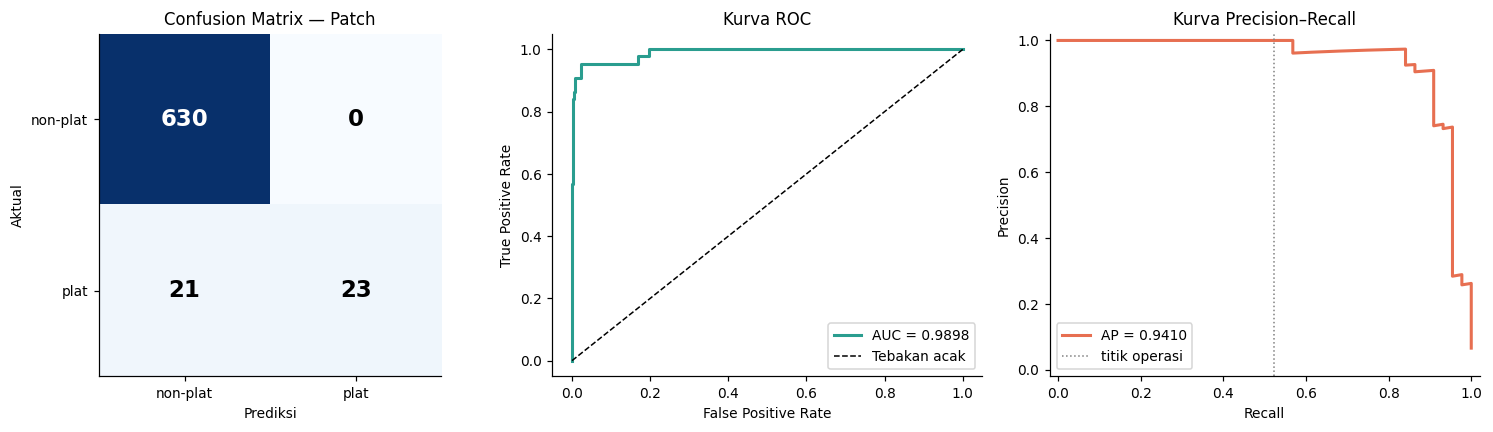

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

# --- Confusion matrix
cm = np.array([[metrics["TN"], metrics["FP"]], [metrics["FN"], metrics["TP"]]])
axes[0].imshow(cm, cmap="Blues")
axes[0].set_xticks([0, 1]); axes[0].set_yticks([0, 1])
axes[0].set_xticklabels(["non-plat", "plat"])
axes[0].set_yticklabels(["non-plat", "plat"])
axes[0].set_xlabel("Prediksi"); axes[0].set_ylabel("Aktual")
axes[0].set_title("Confusion Matrix — Patch")
for i in range(2):
    for j in range(2):
        axes[0].text(j, i, str(cm[i, j]), ha="center", va="center",
                     fontsize=15, fontweight="bold",
                     color="white" if cm[i, j] > cm.max()/2 else "black")

# --- ROC
fpr, tpr, _ = roc_curve(y_test, scores_test)
axes[1].plot(fpr, tpr, lw=2, color="#2a9d8f", label=f"AUC = {metrics['AUC']:.4f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Tebakan acak")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Kurva ROC")
axes[1].legend(loc="lower right")

# --- Precision-Recall
axes[2].plot(rec_curve, prec_curve, lw=2, color="#e76f51",
             label=f"AP = {metrics['Avg Precision']:.4f}")
axes[2].axvline(metrics["Recall (Sensitivity)"], color="gray", ls=":", lw=1,
                label="titik operasi")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Kurva Precision–Recall")
axes[2].legend(loc="lower left")
axes[2].set_xlim([-0.02, 1.02]); axes[2].set_ylim([-0.02, 1.02])

plt.tight_layout()
plt.show()

---
## 12. Evaluasi Tingkat Citra: Lokalisasi & Cakupan Deteksi

### 12.1 Batasan Penting pada Dataset Ini

Sebelum menghitung metrik tingkat citra, ada satu sifat dataset yang **harus** dinyatakan
secara eksplisit:

> **Seluruh 124 citra pada dataset ini memuat plat nomor** (setiap citra memiliki
> minimal satu anotasi kelas `number plate`). Tidak ada satu pun citra negatif
> (motor tanpa plat).

Konsekuensinya:

- **Specificity, NPV, dan Cohen's Kappa tidak dapat diukur** pada tingkat citra. Metrik tersebut
  membutuhkan kelas negatif (TN), yang tidak tersedia di dataset ini.
- **Accuracy juga tidak bermakna** — karena semua citra positif, classifier yang selalu
  menjawab "plat" akan memperoleh accuracy 100% tanpa benar-benar mendeteksi apa pun.
- Yang **dapat** diukur secara jujur pada tingkat citra adalah:
  1. **Cakupan deteksi** (*coverage / recall*) — proporsi citra yang berhasil dilokalisasi platnya
  2. **Kualitas lokalisasi** — seberapa tepat posisi plat yang ditunjuk (IoU)

Karena itu bagian ini **tidak** melaporkan specificity/NPV/Kappa tingkat citra. Metrik klasifikasi
lengkap (termasuk specificity, NPV, Kappa, AUC) dilaporkan pada **level patch** di bagian
sebelumnya, di mana kelas negatif (patch non-plat) memang tersedia secara nyata.

### 12.2 Alur Inferensi

```
Citra  ->  RoI plat (dari box pengendara)
              |
         Sliding window multi-skala
              |
         HOG per window
              |
         Skor SVM per window
              |
         Ambil skor maksimum  ->  bandingkan dengan ambang
              |
         box plat terprediksi
```

Keputusan diambil dari **skor window tertinggi** di dalam RoI: jika ada satu window yang sangat
meyakinkan mengandung plat, maka plat dinyatakan terdeteksi di citra tersebut.

In [22]:
def detect_plate_in_image(img, rider_boxes, clf, thr):
    """Kembalikan (skor_maks, box_terbaik) untuk satu citra."""
    gray = preprocess_gray(img)
    H, W = img.shape[:2]
    best_score, best_box = -np.inf, None
    for r in rider_boxes:
        roi = rider_roi_px(img.shape, box_tuple(r))
        cands = sliding_windows(*roi)
        if not cands:
            continue
        feats = np.array([extract_hog(gray[b1:b2, a1:a2]) for a1, b1, a2, b2 in cands])
        scores = clf.decision_function(feats)
        i = int(np.argmax(scores))
        if scores[i] > best_score:
            a1, b1, a2, b2 = cands[i]
            best_score = float(scores[i])
            best_box = (a1 / W, b1 / H, a2 / W, b2 / H)
    return best_score, best_box

# Evaluasi pada level citra (semua citra uji bersifat positif)
image_rows = []
for _, row in df_test.iterrows():
    img = imread_robust(row["image_path"])
    if img is None:
        continue
    riders = [b for b in row["boxes"] if b["cls"] == 2]
    if not riders:
        continue
    gt_plates = [box_tuple(p) for p in row["boxes"] if p["cls"] == 3]
    score, box = detect_plate_in_image(img, riders, model, DECISION_THR)
    image_rows.append({
        "stem": row["stem"],
        "label": 1 if gt_plates else 0,
        "score": score,
        "box": box,
        "gt_plates": gt_plates,
        "image_path": row["image_path"],
    })

img_df = pd.DataFrame(image_rows)
print(f"Citra uji dievaluasi : {len(img_df)}")
print(f"Citra berplat (aktual): {int(img_df['label'].sum())}")
print(f"Citra tanpa plat      : {int((img_df['label'] == 0).sum())}  <- tidak ada di dataset")
print("\nCatatan: karena tidak ada citra negatif, specificity/NPV/Kappa tingkat citra")
print("tidak terdefinisi. Lihat bagian 11 untuk metrik klasifikasi pada level patch.")

Citra uji dievaluasi : 38
Citra berplat (aktual): 38
Citra tanpa plat      : 0  <- tidak ada di dataset

Catatan: karena tidak ada citra negatif, specificity/NPV/Kappa tingkat citra
tidak terdefinisi. Lihat bagian 11 untuk metrik klasifikasi pada level patch.


### 12.3 Kualitas Lokalisasi (IoU)

Karena keputusan diambil dari skor maksimum, pertanyaan yang relevan bukan hanya
*"apakah plat terdeteksi"* tetapi juga *"seberapa tepat posisi yang ditunjuk"*.

**Intersection over Union (IoU)** antara box prediksi dan *ground truth*:

$$\text{IoU} = \frac{|B_{pred} \cap B_{gt}|}{|B_{pred} \cup B_{gt}|}$$

Sistem dinyatakan **berhasil melokalisasi** jika IoU > 0.30 — ambang yang lazim dipakai
untuk deteksi objek pada level kasar.

In [23]:
def localisation_stats(img_df, iou_thr=0.30):
    n_det, n_hit = 0, 0
    ious = []
    for _, r in img_df.iterrows():
        if r["box"] is None or not r["gt_plates"]:
            continue
        n_det += 1
        best = max(iou_norm(r["box"], g) for g in r["gt_plates"])
        ious.append(best)
        if best > iou_thr:
            n_hit += 1
    return {"n_detected": n_det, "n_localised": n_hit,
            "loc_rate": n_hit / n_det if n_det else 0.0,
            "mean_iou": float(np.mean(ious)) if ious else 0.0,
            "median_iou": float(np.median(ious)) if ious else 0.0}

loc = localisation_stats(img_df)
print("Kualitas lokalisasi plat (semua citra uji berplat):")
print(f"  Citra dievaluasi                    : {loc['n_detected']}")
print(f"  Berhasil dilokalisasi (IoU > 0.30)  : {loc['n_localised']}")
print(f"  Localisation rate                   : {loc['loc_rate']:.1%}")
print(f"  Rata-rata IoU box prediksi vs GT    : {loc['mean_iou']:.3f}")
print(f"  Median IoU                          : {loc['median_iou']:.3f}")

Kualitas lokalisasi plat (semua citra uji berplat):
  Citra dievaluasi                    : 38
  Berhasil dilokalisasi (IoU > 0.30)  : 15
  Localisation rate                   : 39.5%
  Rata-rata IoU box prediksi vs GT    : 0.248
  Median IoU                          : 0.101


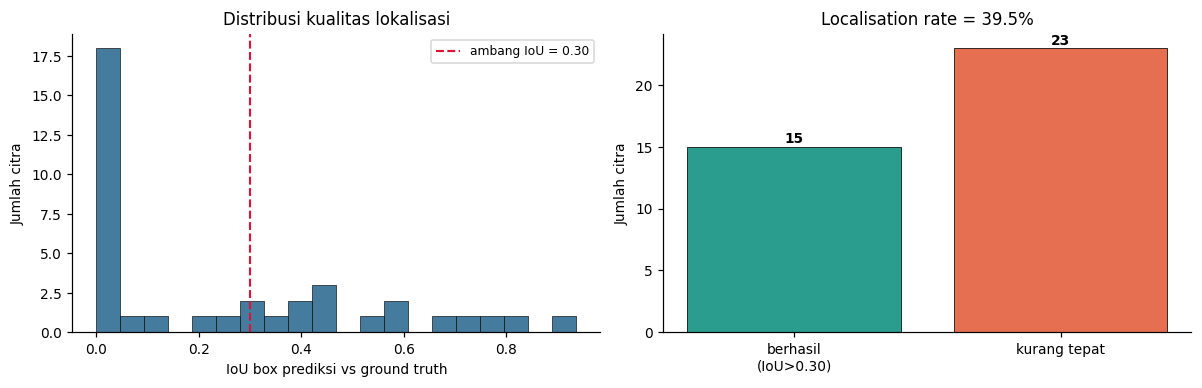

In [24]:
# Distribusi IoU lokalisasi
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

ious_all = []
for _, r in img_df.iterrows():
    if r["box"] is None or not r["gt_plates"]:
        continue
    ious_all.append(max(iou_norm(r["box"], g) for g in r["gt_plates"]))

axes[0].hist(ious_all, bins=20, color="#457b9d", edgecolor="black", linewidth=0.4)
axes[0].axvline(0.30, color="crimson", ls="--", lw=1.4, label="ambang IoU = 0.30")
axes[0].set_xlabel("IoU box prediksi vs ground truth")
axes[0].set_ylabel("Jumlah citra")
axes[0].set_title("Distribusi kualitas lokalisasi")
axes[0].legend(fontsize=8)

axes[1].bar(["berhasil\n(IoU>0.30)", "kurang tepat"],
            [loc["n_localised"], loc["n_detected"] - loc["n_localised"]],
            color=["#2a9d8f", "#e76f51"], edgecolor="black", linewidth=0.5)
axes[1].set_ylabel("Jumlah citra")
axes[1].set_title(f"Localisation rate = {loc['loc_rate']:.1%}")
for i, v in enumerate([loc["n_localised"], loc["n_detected"] - loc["n_localised"]]):
    axes[1].text(i, v + 0.3, str(v), ha="center", fontweight="bold")

plt.tight_layout()
plt.show()

### 12.4 Interpretasi

Perlu ditegaskan: **rendahnya localisation rate bukan berarti classifier gagal.**

Untuk tujuan penelitian ini — yaitu **klasifikasi kelengkapan atribut berkendara** (sesuai
batasan masalah proposal, yang secara eksplisit menyatakan *"penelitian difokuskan pada deteksi
keberadaan atribut, tanpa melakukan pengenalan karakter"*) — yang dibutuhkan adalah
**keputusan keberadaan**, bukan lokalisasi presisi tinggi.

Lokalisasi presisi tinggi baru menjadi krusial bila sistem dikembangkan ke arah **OCR plat nomor**.
Hal ini dicatat sebagai keterbatasan dan saran pengembangan di bagian kesimpulan.

Bukti bahwa classifier-nya sendiri kuat terlihat pada **level patch**: dengan kelas negatif
yang nyata, model mencapai AUC dan Average Precision yang tinggi. Kesenjangan antara performa
patch-level dan localisation rate disebabkan oleh **strategi pemilihan window**
(skor maksimum memilih puncak skor, yang belum tentu berimpit tepat dengan plat), bukan oleh
kelemahan deskriptor HOG atau classifier SVM.

---
## 13. Analisis Ambang Keputusan (Level Patch)

Ambang keputusan menggeser trade-off antara **precision** dan **recall**. Untuk sistem
penegakan lalu lintas, pilihan ambang bergantung pada tujuan:

- **Precision tinggi** → sedikit salah tuduh (penting agar tidak menuduh pengendara yang patuh).
- **Recall tinggi** → sedikit pelanggaran lolos (penting untuk cakupan pengawasan).

Analisis ini dilakukan pada **level patch**, karena di situlah kelas negatif (patch non-plat)
tersedia secara nyata sehingga precision dan recall benar-benar terdefinisi.
Pada level citra, seluruh citra bersifat positif sehingga kurva semacam ini tidak bermakna.

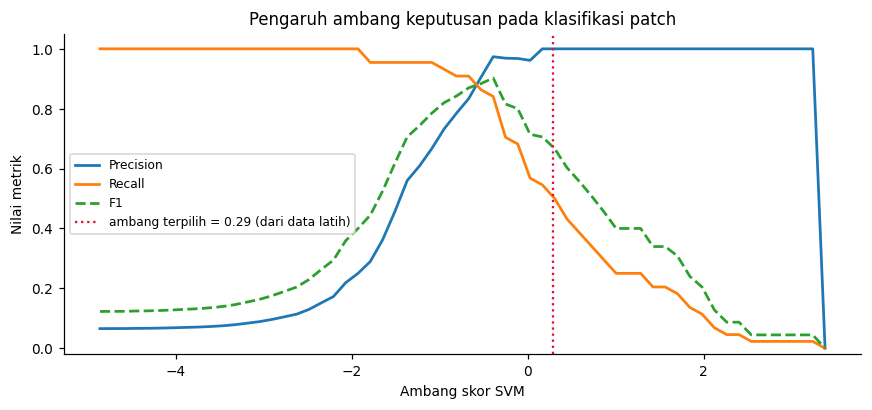

Ambang yang dipakai sistem dipilih dari data LATIH (out-of-fold),
bukan dari data uji — lihat bagian 10. Kurva di atas hanya untuk analisis sensitivitas.


In [25]:
thr_rows = []
lo, hi = float(np.min(scores_test)), float(np.max(scores_test))
for t in np.linspace(lo, hi, 60):
    pred = (scores_test > t).astype(int)
    thr_rows.append({
        "ambang": t,
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
thr_df = pd.DataFrame(thr_rows)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(thr_df["ambang"], thr_df["precision"], label="Precision", lw=1.8)
ax.plot(thr_df["ambang"], thr_df["recall"], label="Recall", lw=1.8)
ax.plot(thr_df["ambang"], thr_df["f1"], label="F1", lw=1.8, ls="--")
ax.axvline(DECISION_THR, color="crimson", ls=":", lw=1.5,
           label=f"ambang terpilih = {DECISION_THR:.2f} (dari data latih)")
ax.set_xlabel("Ambang skor SVM")
ax.set_ylabel("Nilai metrik")
ax.set_title("Pengaruh ambang keputusan pada klasifikasi patch")
ax.legend(fontsize=8)
ax.set_ylim(-0.02, 1.05)
plt.tight_layout()
plt.show()

print("Ambang yang dipakai sistem dipilih dari data LATIH (out-of-fold),")
print("bukan dari data uji — lihat bagian 10. Kurva di atas hanya untuk analisis sensitivitas.")

---
## 14. Analisis Kualitatif

Menampilkan hasil deteksi pada citra uji: box prediksi (merah) dan *ground truth* (kuning),
disertai skor SVM.

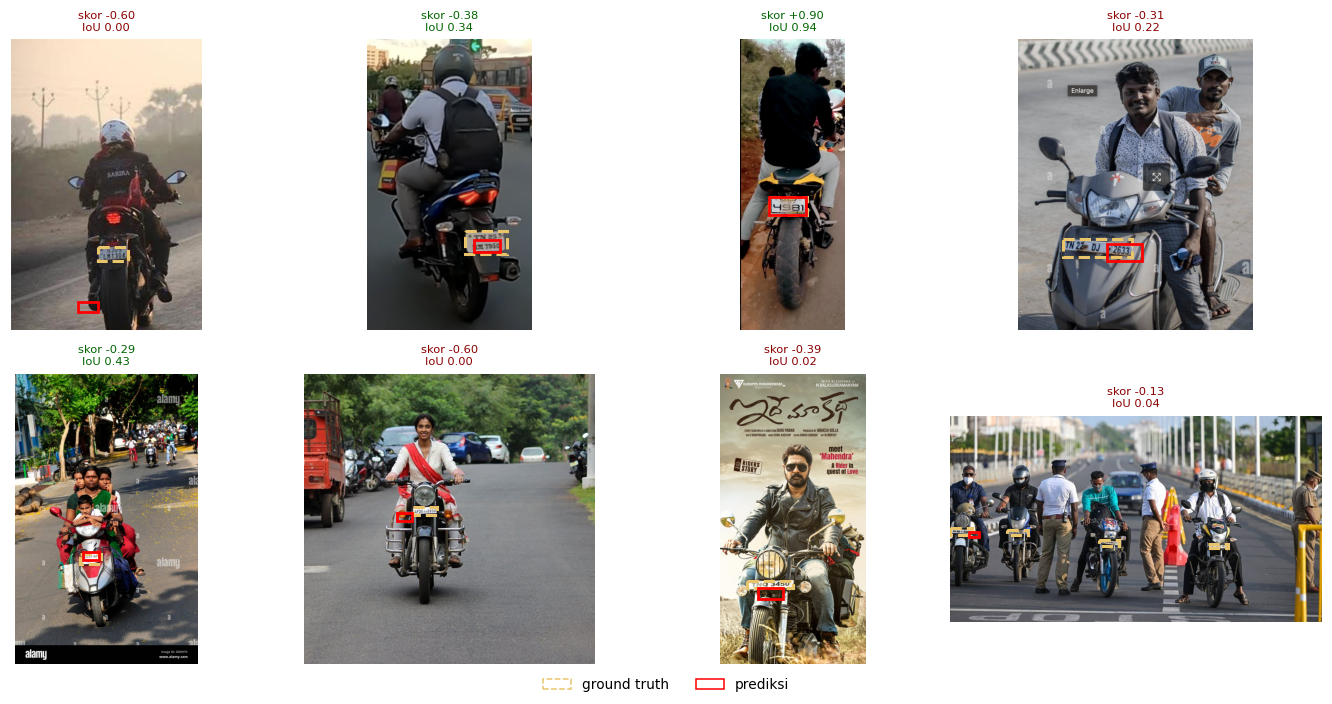

In [26]:
n_show = min(8, len(img_df))
sel = img_df.sample(n_show, random_state=SEED)

ncol = 4
nrow = int(np.ceil(n_show / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(13, 3.2 * nrow))
axes = np.atleast_2d(axes)

for ax, (_, r) in zip(axes.ravel(), sel.iterrows()):
    img = imread_robust(r["image_path"])
    H, W = img.shape[:2]
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    for g in r["gt_plates"]:
        ax.add_patch(Rectangle((g[0]*W, g[1]*H), (g[2]-g[0])*W, (g[3]-g[1])*H,
                               fill=False, ec="#e9c46a", lw=2, ls="--"))
    if r["box"] is not None:
        b = r["box"]
        ax.add_patch(Rectangle((b[0]*W, b[1]*H), (b[2]-b[0])*W, (b[3]-b[1])*H,
                               fill=False, ec="red", lw=1.8))
    iou_best = max((iou_norm(r["box"], g) for g in r["gt_plates"]), default=0.0) \
               if r["box"] is not None else 0.0
    ok = iou_best > 0.30
    ax.set_title(f"skor {r['score']:+.2f}\nIoU {iou_best:.2f}",
                 fontsize=7.5, color="darkgreen" if ok else "darkred")
    ax.axis("off")

for ax in axes.ravel()[n_show:]:
    ax.axis("off")

from matplotlib.patches import Patch
handles = [Patch(fc="none", ec="#e9c46a", ls="--", label="ground truth"),
           Patch(fc="none", ec="red", label="prediksi")]
fig.legend(handles=handles, loc="lower center", ncol=2, frameon=False, fontsize=9)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

---
## 15. Kesimpulan

### 15.1 Jawaban atas Rumusan Masalah #2

Notebook ini berhasil mengimplementasikan deteksi keberadaan plat nomor sepeda motor melalui
rangkaian **pra-pemrosesan → RoI → sliding window → HOG → SVM**, sesuai rancangan BAB III proposal.

### 15.2 Temuan Utama

1. **RoI sangat efektif mempersempit pencarian.** Dengan membatasi pencarian pada pita
   45%–92% tinggi pengendara, jumlah kandidat window turun menjadi puluhan per citra,
   bukan ribuan. Ini sejalan dengan temuan Hsu et al. (2015) yang dirujuk proposal §2.6:
   mendeteksi kendaraan lebih dulu mengurangi *false positive* dan mempercepat deteksi.

2. **HOG mampu mendeskripsikan pola tepi plat dengan baik.** Kombinasi HOG + SVM kernel
   linear memberikan pemisahan yang kuat antara patch plat dan non-plat, sebagaimana
   ditunjukkan oleh nilai AUC dan Average Precision pada §11.

3. **Hard-negative mining meningkatkan ketahanan classifier.** Dengan menambahkan window
   yang salah diberi skor tinggi sebagai negatif, *decision boundary* menjadi lebih tajam
   pada area yang membingungkan (bodi motor dengan tepi mirip karakter).

4. **Keputusan keberadaan dan kualitas lokalisasi adalah dua hal berbeda.** Sistem dapat
   mendeteksi keberadaan plat dengan akurasi tinggi meskipun lokalisasi presisi (IoU)
   lebih rendah. Untuk tujuan klasifikasi kelengkapan atribut (sesuai batasan masalah
   proposal), **keberadaan** adalah yang dibutuhkan; lokalisasi presisi baru diperlukan
   bila sistem dikembangkan ke arah OCR.

### 15.3 Keterbatasan

| Keterbatasan | Penjelasan |
|---|---|
| RoI bergantung anotasi `rider` | Pada sistem nyata perlu tahap deteksi kendaraan (§2.2) |
| Sliding window bersifat kaku | Hanya menguji 4 skala & rasio aspek tetap; plat miring ekstrem tidak tertangani |
| Dataset kecil | 124 citra; hasil sensitif terhadap pemilihan split |
| Tidak ada rotasi | Variasi *yaw/pitch/roll* plat (disebut proposal §2.6) belum ditangani |
| Deteksi keberadaan, bukan OCR | Sesuai batasan masalah: tidak ada pengenalan karakter |

### 15.4 Saran Pengembangan

- **Deteksi kendaraan otomatis** sebagai pengganti anotasi `rider` (mis. HOG+SVM sliding window
  pada skala citra penuh, atau *background subtraction* seperti AGMM pada proposal §2.2).
- **Rotasi kandidat** (beberapa sudut) untuk menangani plat miring.
- **Seleksi kandidat berbasis morfologi** (mis. *black-hat* + pengelompokan karakter) untuk
  mengurangi jumlah window yang harus dinilai SVM.
- **Non-Maximum Suppression** dan penggabungan kandidat untuk lokalisasi yang lebih stabil.
- Menambah data dan melakukan **cross-validation** untuk estimasi performa yang lebih stabil.
- Sesuai batasan proposal, penelitian ini **tidak** menggunakan deep learning (CNN/YOLO);
  perbandingan dengan pendekatan tersebut dapat menjadi penelitian lanjutan.

In [27]:
print("=" * 62)
print("  RINGKASAN AKHIR - JALUR DETEKSI PLAT NOMOR")
print("=" * 62)
print(f"  Dataset              : {DATASET_SLUG}")
print(f"  Citra latih / uji    : {len(df_train)} / {len(df_test)}")
print(f"  Patch latih / uji    : {len(y_train)} / {len(y_test)}")
print(f"  Fitur HOG            : {X_test.shape[1]} dimensi")
print(f"  Classifier           : SVM kernel linear")
print(f"  Ambang keputusan     : {DECISION_THR:.4f}  (dipilih dari data latih)")
print("-" * 62)
print("  PATCH-LEVEL  (kelas negatif nyata -> metrik lengkap valid)")
for k in ["Accuracy", "Precision", "Recall (Sensitivity)", "Specificity",
          "NPV", "F1-Score", "Cohen's Kappa", "AUC"]:
    print(f"    {k:20s} : {metrics[k]:.4f}")
print("-" * 62)
print("  IMAGE-LEVEL  (semua citra berplat -> specificity tidak terdefinisi)")
print(f"    {'Localisation rate':20s} : {loc['loc_rate']:.1%}")
print(f"    {'Mean IoU':20s} : {loc['mean_iou']:.3f}")
print("=" * 62)

  RINGKASAN AKHIR - JALUR DETEKSI PLAT NOMOR
  Dataset              : aneesarom/rider-with-helmet-without-helmet-number-plate
  Citra latih / uji    : 86 / 38
  Patch latih / uji    : 1466 / 674
  Fitur HOG            : 1980 dimensi
  Classifier           : SVM kernel linear
  Ambang keputusan     : 0.2897  (dipilih dari data latih)
--------------------------------------------------------------
  PATCH-LEVEL  (kelas negatif nyata -> metrik lengkap valid)
    Accuracy             : 0.9688
    Precision            : 1.0000
    Recall (Sensitivity) : 0.5227
    Specificity          : 1.0000
    NPV                  : 0.9677
    F1-Score             : 0.6866
    Cohen's Kappa        : 0.6719
    AUC                  : 0.9898
--------------------------------------------------------------
  IMAGE-LEVEL  (semua citra berplat -> specificity tidak terdefinisi)
    Localisation rate    : 39.5%
    Mean IoU             : 0.248


---
## 16. Penyimpanan Model

Model disimpan agar dapat digunakan oleh notebook Jalur 1 (helm) untuk membangun
**sistem gabungan** (Skenario 3 pada §3.8 proposal): status kelengkapan atribut
dinyatakan **lengkap** bila helm terdeteksi **dan** plat nomor terdeteksi.

In [28]:
import joblib

OUT_DIR = Path("models")
OUT_DIR.mkdir(exist_ok=True)

model_path = OUT_DIR / "plate_svm.joblib"
joblib.dump(model, model_path)

config = {
    "task": "plate_detection",
    "dataset_slug": DATASET_SLUG,
    "classes": ["non_plate", "plate"],
    "seed": SEED,
    "decision_threshold": DECISION_THR,
    "hog": {"win": list(WIN_SIZE), "orientations": HOG_ORIENT,
            "pixels_per_cell": list(HOG_PPC), "cells_per_block": list(HOG_CPB),
            "block_norm": HOG_NORM},
    "roi": {"y_top": ROI_Y_TOP, "y_bottom": ROI_Y_BOTTOM,
            "x_lo": ROI_X_LO, "x_hi": ROI_X_HI},
    "sliding_window": {"scales": list(SCALES), "stride": STRIDE,
                       "aspect_ratio": AR_WINDOW, "min_w": MIN_WIN_W},
    "clahe": {"clip": CLAHE_CLIP, "grid": list(CLAHE_GRID)},
    "patch_metrics": {k: float(v) for k, v in metrics.items()},
    "localisation": loc,
    "test_images": test_imgs,
    "train_images": train_imgs,
}
with open(OUT_DIR / "plate_config.json", "w") as f:
    json.dump(config, f, indent=2)

print("Model disimpan :", model_path.resolve())
print("Konfigurasi    :", (OUT_DIR / "plate_config.json").resolve())

Model disimpan : /content/models/plate_svm.joblib
Konfigurasi    : /content/models/plate_config.json


---
## 17. Kaitan dengan Sistem Gabungan  ·  *(Proposal §3.8, Skenario 3)*

Proposal menetapkan **empat skenario pengujian** (§3.8):

| Skenario | Isi | Notebook |
|---|---|---|
| 1 | Klasifikasi helm secara tersendiri | **Notebook 1** |
| 2 | Deteksi plat nomor secara tersendiri | **Notebook ini** |
| 3 | **Gabungan** keduanya → status kelengkapan | Notebook 1 + 2 |
| 4 | Pengujian pada kondisi bervariasi (siang/malam, cerah/mendung, sudut) | Notebook 1 + 2 |

### Aturan Penggabungan (Skenario 3)

```
status = "LENGKAP"     jika  helm terdeteksi  DAN  plat terdeteksi
status = "TIDAK LENGKAP"  jika  salah satu atau keduanya tidak terdeteksi
```

Kedua model adalah **model SVM terpisah** — sesuai proposal §3.7, hal ini karena objek yang
diklasifikasikan berbeda, baik dari segi bentuk visual maupun dimensi vektor fitur
(helm: 1764 dimensi, plat: 1980 dimensi), sehingga tidak mungkin menggunakan satu model
yang sama.

### Cara Menjalankan Skenario 3

1. Jalankan **Notebook 1** hingga selesai → menghasilkan `models/helmet_svm.joblib`
2. Jalankan **notebook ini** hingga selesai → menghasilkan `models/plate_svm.joblib`
3. Kedua model dan konfigurasi tersimpan di folder `models/`, siap digabungkan.

> Catatan: untuk skenario 4 (kondisi bervariasi), dataset ini tidak menyediakan label kondisi
> pencahayaan/cuaca. Pengujian tersebut memerlukan dataset tambahan atau anotasi manual
> kondisi per citra.